---
## **0. 준비**
---

In [ ]:
%%html
<style>
    body {
        /* change --vscode-font-family if it's different on your system */
        --vscode-font-family: "SeoulNamsanC";
    }
</style>

In [1]:
from langchain_openai import ChatOpenAI
from langchain_google_genai import GoogleGenerativeAI

In [2]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from IPython.display import display, Markdown

In [3]:
import config
config.set_environment()

---
## **(매우 중요) 지금까지 배운 요소를 하나의 워크플로로 통합**

**목표:** 채용 공고를 입력받아 주니어 자바 개발자에게 적합한지 판단하고, 적합할 때만 지원서 생성 단계로 진행한다. 현재 공고 분석에는 실제 LLM을 사용하고, 지원서는 고정된 예시 문자열을 반환한다.

```text
초기 상태: job_description
    ↓
공고분석: 공고로 프롬프트 구성 → LLM → Enum 파싱
    │     is_suitable 갱신 + action1 누적
    ↓
조건부 에지: IsSuitableJobEnum.YES인가?
    ├─ False → 종료
    └─ True → 지원서생성: 예시 지원서 저장 + action2 누적 → 종료
```

**셀별 현재 구현 내역**

| 셀 | 구성 | 현재 동작 |
|---|---|---|
| -- | 그래프 구조 설계 | `build_graph()`에 두 노드와 조건부 에지를 정의. 함수를 정의하는 시점에는 그래프를 빌드하지 않음 |
| -- | Enum·파서·상태·리듀서 | YES/NO Enum과 파서를 정의하고, 상태에 공고·판단 결과·지원서·액션 목록을 선언. `my_reducer`가 액션을 누적 |
| -- | 분석 체인 | 고정 모델 `gpt-6-luna`와 파서를 `llm | parser`로 연결. 프롬프트는 문자열 템플릿으로 정의 |
| -- | 노드와 분기 함수 | 분석 노드는 `.format()`으로 공고를 채우고 체인을 호출. 조건 함수는 Enum 비교 결과를 반환. 생성 노드는 설정을 읽고 예시 지원서를 반환 |
| -- | 그래프 빌드·시각화 | 필요한 함수가 준비된 후 `build_graph()`를 호출하고 실제 연결 구조를 그림으로 확인 |
| -- | 한 번의 실행과 상태 수집 | `astream(stream_mode="values")`로 초기 상태와 슈퍼스텝별 전체 상태를 `state_history`에 수집. 정상 종료 후 마지막 상태를 `res`에 저장 |
| -- | 저장된 결과 재확인 | `res`에서 적합 여부와 액션을 출력하고, 지원서가 있으면 마크다운으로 표시. 그래프나 모델을 재호출하지 않음 |

**상태에 저장하는 값**

| 키 | 타입 | 값을 채우는 곳 |
|---|---|---|
| `job_description` | `str` | 초기 입력 |
| `is_suitable` | `IsSuitableJobEnum` | 공고분석 노드의 파싱 결과 |
| `application` | `str` | YES 분기의 지원서생성 노드 |
| `actions` | `Annotated[list[str], my_reducer]` | 분석의 `action1`, 생성의 `action2`를 순서대로 누적 |

- **NO 경로:** `actions=["action1"]`. 초기 입력에도 지원서가 없다면 `application` 키는 최종 상태에 없다.
- **YES 경로:** `actions=["action1", "action2"]`, `application="some_fake_application"`.
- `is_suitable`은 불리언이 아니라 Enum이다. 조건 함수에서 YES 멤버와 비교하여 불리언으로 바꾼다.

**설정과 실행을 해석할 때의 주의점**

- `generate_application(state, config: RunnableConfig)`는 LangGraph가 전달한 설정에서 `config.get("configurable", {})`로 사용자 설정을 읽는다. 키가 생략되면 공급자 `OpenAI`, 모델명 `gpt-6-luna`를 기본값으로 사용한다.
- 이 공급자·모델명은 **현재 로그 출력에만 사용**한다. 실제 분석 모델은 19번의 `llm`으로 고정되어 있고, 생성 노드는 아직 LLM을 호출하지 않는다. 설정만 바꿔도 실제 모델이 바뀌는 구조는 아니다.
- 프롬프트는 현재 `PromptTemplate` 객체가 아니라 **문자열의 `.format()`** 으로 구성한다. 현재 목적에는 유효하며, 이후 템플릿 객체를 체인의 첫 단계로 연결할 수 있다.
- 현재 정상 경로에서 22번은 그래프를 한 번 실행하며, 분석 노드에서 모델을 호출한다. 내부 오류 재시도가 없다면 API 요청도 한 번이다. 23번은 표시만 하지만 **22번을 다시 실행하면 새 모델 호출이 발생**한다.
- 현재는 별도 출력 스키마나 실행 중단이 없어 스트림의 마지막 전체 상태를 최종 결과로 사용할 수 있다. `invoke()`를 추가로 호출할 필요는 없다.
- 노드 함수를 수정했다면 20번뿐 아니라 **21번 그래프 빌드도 다시 실행**한 뒤 22번으로 진행한다. 이전 그래프 객체는 이전 함수 객체를 참조할 수 있다.

**다음에 확장할 부분:** 지원서생성 노드를 실제 생성 체인에 연결하기, 설정으로 모델을 선택하도록 구현하기, 파싱 오류·API 오류 처리 추가하기.


In [83]:
# 0) 필요 모듈, 함수, 클래스 불러오기
from langgraph.graph import StateGraph, START, END                          
from typing import TypedDict                                                
from langchain_classic.output_parsers import EnumOutputParser
from langchain_openai import ChatOpenAI
from typing import Annotated, Optional, Union
from langchain_core.runnables.config import RunnableConfig

# 1) 전체 구조 및 흐름 설계
def build_graph():
    builder = StateGraph(JobApplicationState)

    # 필요 노드 추가
    builder.add_node("공고분석", analyze_jd)
    builder.add_node("지원서생성", generate_application)

    # 흐름 설계(엣지)
    builder.add_edge(START, "공고분석")
    builder.add_conditional_edges("공고분석", is_suitable_condition,
                                  {True:"지원서생성", False:END})
    builder.add_edge("지원서생성", END)

    return builder.compile()

In [84]:
# 1-2) 상태 스키마 구현
    # 필요시 사용자 정의 reducer, add 메서드 등 구성

def my_reducer(
    left: list[str],
    right: Optional[Union[str, list[str]]],) -> list[str]:
    if right:
        return left + [right] if isinstance(right, str) else left + right
    return left

    # 상태 스키마 정의
class IsSuitableJobEnum(Enum):
    YES = "YES"                                        
    NO = "NO"
parser = EnumOutputParser(enum=IsSuitableJobEnum)      

class JobApplicationState(TypedDict):
    job_description:str
    is_suitable: IsSuitableJobEnum
    application: str
    actions: Annotated[list[str], my_reducer]
    

In [ ]:
# 2-1) llm 응답/판단/생성이 필요한 부분 chain 구성
    # llm 모델 구성:
llm = ChatOpenAI(model = "gpt-6-luna", use_responses_api=True)
    # 분석 체인 구조
analyze_chain = llm | parser

# 2-2) 필요한 프롬프트 템플릿화
    # 분석 노드에서 필요한 템플릿 -> 문자열이 아닌 `PromptTemplate` 객체로 진행하는 방법으로 수정 가능?
prompt_template_enum = (
    "전달하는 JD를 보고 주니어 자바에 적당한지 결정해봐."
    "\nJob Description:\n{JD}\n"
    "\nAnswer only YES or NO.")


In [ ]:
# 2-2) 흐름에 필요한 기능 구현(함수)
def analyze_jd(state):
    '''llm 판단 필요 -> chain 구성할 것'''
    prompt = prompt_template_enum.format(JD=state["job_description"])       #문자열이 아닌 `PromptTemplate` 객체로 진행하는 방법으로 수정 가능?
    result = analyze_chain.invoke(prompt)    
    return {"is_suitable":result, 
            "actions":["action1"]}

def is_suitable_condition(state:JobApplicationState):
    return state["is_suitable"] == IsSuitableJobEnum.YES

def generate_application(state, config: RunnableConfig):
    # configurable이 생략되었으면 빈 딕셔너리를 사용합니다.
    options = config.get("configurable", {})
    model_provider = options.get("model_provider", "OpenAI")
    model_name = options.get("model_name", "gpt-6-luna")
    # 아래 설정은 현재 로그에만 사용됩니다. 실제 모델 생성·호출 코드는 아직 없습니다.
    print(f"...generating application with {model_provider} and {model_name}...")
    return {"application": "some_fake_application", 
            "actions":["action2"]}


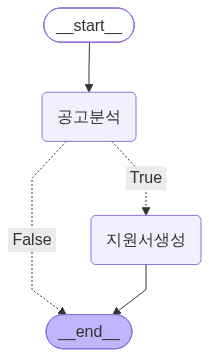

In [87]:
# 보조) 구조 확인하기 위한 
from IPython.display import Image, display
graph = build_graph()
display(Image(graph.get_graph().draw_mermaid_png()))

In [88]:
# 그래프를 한 번 실행하면서 중간 상태와 최종 상태를 모두 확인합니다.
# invoke()를 별도로 호출하면 새 실행이므로, 여기서는 astream()만 사용합니다.
job_description : str = """백엔드 개발 경력 7년 이상의 자바 소프트웨어 엔지니어를 모집합니다. 지원자는 분산 시스템, 마이크로서비스 아키텍쳐, 성능 튜닝 및 대규모 시스템 설계에 대한 심도 있는 지식을 보유해야 합니다..."""

state_history = []  # 이번 실행의 상태를 저장하여 나중에 다시 살펴봅니다.
res = None         # 실행 실패 시 이전 실행의 최종 결과를 잘못 읽지 않도록 초기화합니다.

async for chunk in graph.astream(
    input={"job_description": job_description},
    stream_mode="values",
):
    state_history.append(chunk)
    print(f"[상태 {len(state_history) - 1}]", chunk)  # 상태 0은 초기 상태입니다.

# 스트림이 정상적으로 끝난 뒤 마지막 전체 상태를 최종 결과로 사용합니다.
# 현재 그래프는 입출력 스키마가 같아 invoke()의 최종 결과에 해당합니다.
# 별도 출력 스키마나 실행 중단을 설정하면 추가 처리가 필요할 수 있습니다.
res = state_history[-1] if state_history else None
print("\n[최종 결과]", res)


[상태 0] {'job_description': '백엔드 개발 경력 7년 이상의 자바 소프트웨어 엔지니어를 모집합니다. 지원자는 분산 시스템, 마이크로서비스 아키텍쳐, 성능 튜닝 및 대규모 시스템 설계에 대한 심도 있는 지식을 보유해야 합니다...', 'actions': []}
[상태 1] {'job_description': '백엔드 개발 경력 7년 이상의 자바 소프트웨어 엔지니어를 모집합니다. 지원자는 분산 시스템, 마이크로서비스 아키텍쳐, 성능 튜닝 및 대규모 시스템 설계에 대한 심도 있는 지식을 보유해야 합니다...', 'is_suitable': <IsSuitableJobEnum.NO: 'NO'>, 'actions': ['action1']}

[최종 결과] {'job_description': '백엔드 개발 경력 7년 이상의 자바 소프트웨어 엔지니어를 모집합니다. 지원자는 분산 시스템, 마이크로서비스 아키텍쳐, 성능 튜닝 및 대규모 시스템 설계에 대한 심도 있는 지식을 보유해야 합니다...', 'is_suitable': <IsSuitableJobEnum.NO: 'NO'>, 'actions': ['action1']}


In [89]:
# 22번에서 저장한 실행 결과를 재확인합니다. 모델이나 그래프를 다시 호출하지 않습니다.
from IPython.display import display, Markdown

print("적합 여부:", res.get("is_suitable") if res is not None else "최종 결과 없음")
print("작업 기록:", res.get("actions", []) if res is not None else [])

if res is not None and "application" in res:
    display(Markdown(res["application"]))
else:
    print("지원서가 생성되지 않았습니다. NO 분기에서는 정상입니다.")

# 중간 상태는 state_history[0], state_history[1] 등으로 다시 볼 수 있습니다.


적합 여부: IsSuitableJobEnum.NO
작업 기록: ['action1']
지원서가 생성되지 않았습니다. NO 분기에서는 정상입니다.
